In [1]:
import importlib

modules = [
    'qiskit', 
    'qiskit_aer', 
    'qiskit_ibm_runtime', 
    'matplotlib', 
    'pylatexenc', 
    'numpy', 
    'scipy', 
    'pandas'
]

missing = [mod for mod in modules if importlib.util.find_spec(mod) is None]

if not missing:
    print("All packages are installed and available!")
else:
    print(f"Missing modules: {missing}")

Missing modules: ['pylatexenc', 'pandas']


In [2]:
# Qiskit imports
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import XGate, YGate, ZGate, HGate, SGate, TGate, CXGate
from qiskit.quantum_info import (Statevector, Operator, DensityMatrix, Pauli,partial_trace, entropy, state_fidelity)
from qiskit.result import marginal_counts
from qiskit.transpiler import CouplingMap
from qiskit.visualization import plot_histogram, plot_bloch_vector, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

sim = AerSimulator()          # ideal, noiseless local simulator used throughout
print("Qiskit SDK", qiskit.__version__)

Qiskit SDK 2.5.2


Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))
probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


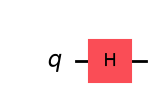

In [3]:
qc = QuantumCircuit(1)
qc.h(0)
sv = Statevector(qc)
print(sv)
print("probabilities:", sv.probabilities_dict())
qc.draw("mpl")

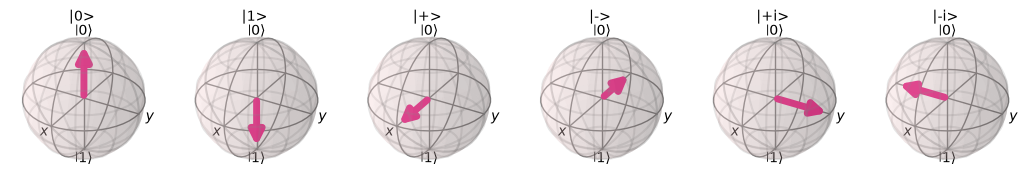

In [6]:
import numpy as np
import matplotlib.pyplot as plt

labels = {"|0>": "0", "|1>": "1", "|+>": "+", "|->": "-", "|+i>": "r", "|-i>": "l"}
vectors = {}
for name, lab in labels.items():
    s = Statevector.from_label(lab)
    vectors[name] = [float(np.real(s.expectation_value(Pauli(p)))) for p in "XYZ"]

try:                                    # one row of six small spheres
    fig = plt.figure(figsize=(13, 2.7))
    for i, (name, vec) in enumerate(vectors.items(), start=1):
        ax = fig.add_subplot(1, 6, i, projection="3d")
        plot_bloch_vector(vec, title=name, ax=ax)
    plt.show()
except Exception:                       # fallback for older Qiskit versions: one figure per state
    plt.close("all")
    for name, vec in vectors.items():
        fig = plot_bloch_vector(vec, title=name, figsize=(2.6, 2.6))
        display(fig); plt.close(fig)